# Lan truyền ngược (backpropagation)

*Bài 9, mục 9.1.3.* Ký hiệu cho lớp $l$: $\mathbf{z}^{(l)} = \mathbf{W}^{(l)}\mathbf{a}^{(l-1)} + \mathbf{b}^{(l)}$, $\mathbf{a}^{(l)} = f(\mathbf{z}^{(l)})$, $\mathbf{a}^{(0)} = \mathbf{x}$. Với lớp ra sigmoid và hàm mất mát cross-entropy:
- $\boldsymbol{\delta}^{(L)} = \mathbf{a}^{(L)} - \mathbf{y}$
- $\boldsymbol{\delta}^{(l)} = (\mathbf{W}^{(l+1)})^T\boldsymbol{\delta}^{(l+1)} \odot f'(\mathbf{z}^{(l)})$
- $\dfrac{\partial \mathcal{L}}{\partial \mathbf{W}^{(l)}} = \boldsymbol{\delta}^{(l)}(\mathbf{a}^{(l-1)})^T$, $\dfrac{\partial \mathcal{L}}{\partial \mathbf{b}^{(l)}} = \boldsymbol{\delta}^{(l)}$

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def sigmoid(z):
    return 1 / (1 + np.exp(-z))

## 1. Ví dụ tính tay: mạng 2 – 2 – 1, một mẫu

Mẫu $\mathbf{x} = (1, 2)$, nhãn $y = 1$; lớp ẩn và lớp ra đều dùng sigmoid; tốc độ học $\eta = 0.5$.

In [2]:
x = np.array([1.0, 2.0])
y = 1.0
W1 = np.array([[0.1, 0.2],
               [-0.3, 0.4]])                 # W^(1): 2 nơ-ron ẩn x 2 đầu vào
b1 = np.array([0.0, 0.1])
W2 = np.array([[0.5, -0.6]])                 # W^(2): 1 nơ-ron ra x 2 nơ-ron ẩn
b2 = np.array([0.2])
eta = 0.5                                    # tốc độ học


def forward(W1, b1, W2, b2):
    z1 = W1 @ x + b1
    a1 = sigmoid(z1)
    z2 = W2 @ a1 + b2
    a2 = sigmoid(z2)
    return z1, a1, z2, a2


def loss(a2):
    return -(y * np.log(a2[0]) + (1 - y) * np.log(1 - a2[0]))     # cross-entropy


z1, a1, z2, a2 = forward(W1, b1, W2, b2)
print('Lan truyền xuôi:')
print('   z1 =', z1.round(4), '  a1 =', a1.round(4))
print('   z2 =', z2.round(4), '  a2 = y_hat =', a2.round(4))
print('   L = %.4f' % loss(a2))

Lan truyền xuôi:
   z1 = [0.5 0.6]   a1 = [0.6225 0.6457]
   z2 = [0.1238]   a2 = y_hat = [0.5309]
   L = 0.6331


In [3]:
delta2 = a2 - y                              # sai số lớp ra
dW2 = np.outer(delta2, a1)
db2 = delta2
delta1 = (W2.T @ delta2) * a1 * (1 - a1)     # lan truyền sai số về lớp ẩn, sigma' = a(1 - a)
dW1 = np.outer(delta1, x)
db1 = delta1
print('Lan truyền ngược:')
print('   delta2 =', delta2.round(4))
print('   dL/dW2 =', dW2.round(4), '  dL/db2 =', db2.round(4))
print('   delta1 =', delta1.round(4))
print('   dL/dW1 =\n', dW1.round(4))
print('   dL/db1 =', db1.round(4))

Lan truyền ngược:
   delta2 = [-0.4691]
   dL/dW2 = [[-0.292  -0.3029]]   dL/db2 = [-0.4691]
   delta1 = [-0.0551  0.0644]
   dL/dW1 =
 [[-0.0551 -0.1102]
 [ 0.0644  0.1288]]
   dL/db1 = [-0.0551  0.0644]


### Kiểm tra gradient bằng đạo hàm số

$\dfrac{\partial \mathcal{L}}{\partial w} \approx \dfrac{\mathcal{L}(w + \varepsilon) - \mathcal{L}(w - \varepsilon)}{2\varepsilon}$ (Bài 5).

In [4]:
eps = 1e-6
numerical = np.zeros_like(W1)
for i in range(2):
    for j in range(2):
        W_plus, W_minus = W1.copy(), W1.copy()
        W_plus[i, j] += eps
        W_minus[i, j] -= eps
        numerical[i, j] = (loss(forward(W_plus, b1, W2, b2)[3]) - loss(forward(W_minus, b1, W2, b2)[3])) / (2 * eps)
print('dL/dW1 bằng đạo hàm số:\n', numerical.round(4))
print('Sai lệch lớn nhất: %.2e' % np.abs(numerical - dW1).max())

dL/dW1 bằng đạo hàm số:
 [[-0.0551 -0.1102]
 [ 0.0644  0.1288]]
Sai lệch lớn nhất: 1.26e-10


### Cập nhật trọng số bằng Gradient Descent

In [5]:
W1_new, b1_new = W1 - eta * dW1, b1 - eta * db1
W2_new, b2_new = W2 - eta * dW2, b2 - eta * db2
print('W2 mới =', W2_new.round(4), ' b2 mới =', b2_new.round(4))
print('W1 mới =\n', W1_new.round(4))
a2_new = forward(W1_new, b1_new, W2_new, b2_new)[3]
print('y_hat: %.4f -> %.4f,  L: %.4f -> %.4f' % (a2[0], a2_new[0], loss(a2), loss(a2_new)))

W2 mới = [[ 0.646  -0.4486]]  b2 mới = [0.4345]
W1 mới =
 [[ 0.1276  0.2551]
 [-0.3322  0.3356]]
y_hat: 0.5309 -> 0.6438,  L: 0.6331 -> 0.4404


## 2. Huấn luyện mạng nhiều lớp bằng NumPy

Dữ liệu hai nửa vầng trăng. Mạng 2 – $H$ – 1: lớp ẩn ReLU, lớp ra sigmoid, cross-entropy, Gradient Descent trên toàn bộ dữ liệu. Mỗi hàng của ma trận là một mẫu, nên $\mathbf{Z}^{(l)} = \mathbf{A}^{(l-1)}\mathbf{W}^{(l)T} + \mathbf{b}^{(l)}$ và gradient lấy trung bình trên $N$ mẫu.

In [6]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=400, noise=0.2, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)


def relu(z):
    return np.maximum(0, z)


def train_mlp(X, y, hidden=10, eta=0.5, epochs=3000, seed=0):
    rng = np.random.default_rng(seed)
    N, d = X.shape
    W1 = rng.normal(0, np.sqrt(2 / d), size=(hidden, d))       # khởi tạo He cho lớp ReLU
    b1 = np.zeros(hidden)
    W2 = rng.normal(0, np.sqrt(1 / hidden), size=(1, hidden))
    b2 = np.zeros(1)
    Y = y.reshape(-1, 1)
    history = []
    for epoch in range(epochs):
        # Lan truyền xuôi
        Z1 = X @ W1.T + b1
        A1 = relu(Z1)
        Z2 = A1 @ W2.T + b2
        A2 = sigmoid(Z2)
        loss = -np.mean(Y * np.log(A2 + 1e-12) + (1 - Y) * np.log(1 - A2 + 1e-12))
        history.append(loss)
        # Lan truyền ngược
        delta2 = (A2 - Y) / N                     # chia N: gradient trung bình
        dW2, db2 = delta2.T @ A1, delta2.sum(axis=0)
        delta1 = (delta2 @ W2) * (Z1 > 0)         # ReLU'(z) = 1 nếu z > 0
        dW1, db1 = delta1.T @ X, delta1.sum(axis=0)
        # Cập nhật trọng số
        W1 -= eta * dW1; b1 -= eta * db1
        W2 -= eta * dW2; b2 -= eta * db2
    return (W1, b1, W2, b2), history


def predict(params, X):
    W1, b1, W2, b2 = params
    return (sigmoid(relu(X @ W1.T + b1) @ W2.T + b2).ravel() >= 0.5).astype(int)


params, history = train_mlp(X_train, y_train, hidden=10)
print('Loss: epoch 1 = %.4f, epoch 100 = %.4f, epoch 3000 = %.4f' % (history[0], history[99], history[-1]))
print('Độ chính xác huấn luyện: %.3f' % (predict(params, X_train) == y_train).mean())
print('Độ chính xác kiểm tra  : %.3f' % (predict(params, X_test) == y_test).mean())

Loss: epoch 1 = 0.6128, epoch 100 = 0.2641, epoch 3000 = 0.0635
Độ chính xác huấn luyện: 0.970
Độ chính xác kiểm tra  : 0.950


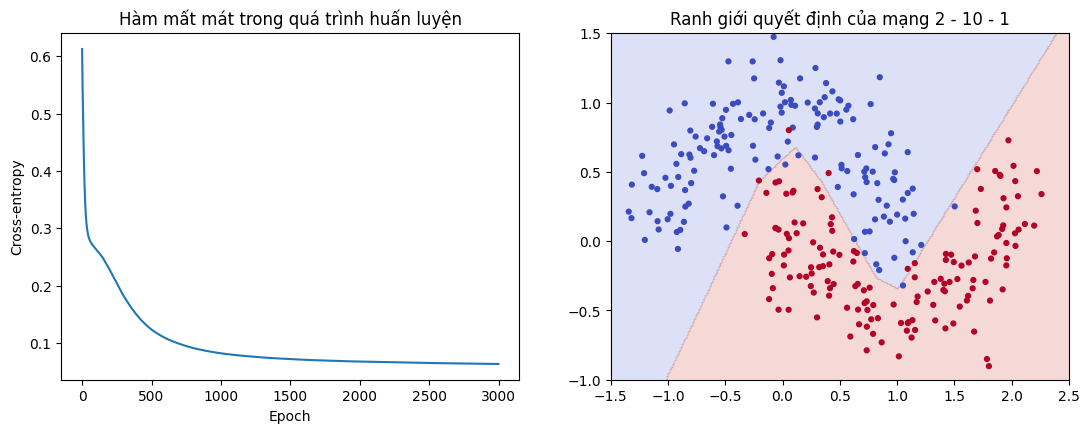

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Cross-entropy')
axes[0].set_title('Hàm mất mát trong quá trình huấn luyện')
xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 300), np.linspace(-1, 1.5, 300))
zz = predict(params, np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[1].contourf(xx, yy, zz, alpha=0.2, cmap='coolwarm')
axes[1].scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', s=12)
axes[1].set_title('Ranh giới quyết định của mạng 2 - 10 - 1')
plt.show()

So sánh với hồi quy Logistic (không có lớp ẩn, ranh giới tuyến tính):

In [8]:
from sklearn.linear_model import LogisticRegression

logistic = LogisticRegression().fit(X_train, y_train)
print('Hồi quy Logistic, độ chính xác kiểm tra: %.3f' % logistic.score(X_test, y_test))
for hidden in [1, 2, 5, 10, 50]:
    params, history = train_mlp(X_train, y_train, hidden=hidden)
    print('Lớp ẩn %2d nơ-ron: loss cuối %.4f, kiểm tra %.3f' % (hidden, history[-1], (predict(params, X_test) == y_test).mean()))

Hồi quy Logistic, độ chính xác kiểm tra: 0.890
Lớp ẩn  1 nơ-ron: loss cuối 0.2959, kiểm tra 0.900


Lớp ẩn  2 nơ-ron: loss cuối 0.2959, kiểm tra 0.900


Lớp ẩn  5 nơ-ron: loss cuối 0.2676, kiểm tra 0.880


Lớp ẩn 10 nơ-ron: loss cuối 0.0635, kiểm tra 0.950


Lớp ẩn 50 nơ-ron: loss cuối 0.0546, kiểm tra 0.950
